# Лабораторная работа №1. Базовый прогноз временно́го ряда (ARIMA)

**Цель.** Разобраться, из чего состоит временной ряд, и запустить простейшую рабочую модель прогноза - ARIMA. Основной код уже написан. Ваша задача - **понять его, запустить на своём варианте, найти в нём недочёты и улучшить**.

**Ваш вариант:** остаток от деления вашего номера в списке на **7** (варианты 0–6). С этой цифры начинается имя вашего файла.

> Полезно к прочтению:
> - Обзорная теория: https://habr.com/ru/companies/otus/articles/732080/
> - Базовая статья работы: https://habr.com/ru/companies/mvideo/articles/769190/
> - Практика с оценкой модели: https://timeweb.cloud/tutorials/python/prognozirovanie-vremennyh-ryadov-python-3

### Шаг 1. Установка библиотек и импорты

In [69]:
# Таблицы, графики и статистические тесты
!pip install pandas numpy matplotlib statsmodels

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller   # тест на стационарность

### Шаг 2. Чтение данных
Подставьте имя файла **своего** варианта.

In [71]:
FILENAME = '0.data-n-09-19.csv'   # <- ЗАМЕНИТЕ на файл своего варианта
data = pd.read_csv(FILENAME)
data

,time,people_amount
0,1.758262e+09,0
1,1.758262e+09,0
2,1.758262e+09,0
3,1.758262e+09,0
4,1.758262e+09,0
...,...,...
8319,1.758305e+09,0
8320,1.758305e+09,0
8321,1.758305e+09,0
8322,1.758305e+09,0


In [72]:
display(data['people_amount'].describe())
display(data[data['people_amount'] > 0].head(10))

count    8324.000000
mean        5.761173
std         7.985458
min         0.000000
25%         0.000000
50%         2.000000
75%         9.000000
max        42.000000
Name: people_amount, dtype: float64

,time,people_amount
8,1.758262e+09,1
23,1.758262e+09,1
24,1.758262e+09,1
26,1.758262e+09,1
27,1.758262e+09,1
28,1.758262e+09,1
29,1.758262e+09,1
30,1.758262e+09,1
31,1.758262e+09,1
41,1.758262e+09,1


### Шаг 3. Взгляд на сырые данные
Всегда сначала смотрим на график.

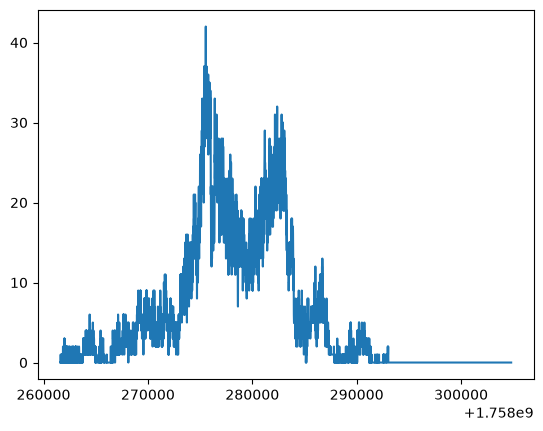

In [73]:
plt.plot(data['time'], data['people_amount'])
plt.show()

### Шаг 4. Перевод времени в дату
Столбец `time` - это Unix-время (секунды с 1970 года). Переводим его в нормальную дату, чтобы на осях были часы, а не гигантские числа.

In [74]:
import datetime
# Переводим каждое значение из "секунд с 1970 года" в дату-время
data['time'] = data['time'].apply(lambda x: datetime.datetime.fromtimestamp(x))
data

,time,people_amount
0,2025-09-19 09:00:04.991900,0
1,2025-09-19 09:00:10.024500,0
2,2025-09-19 09:00:15.031300,0
3,2025-09-19 09:00:20.038100,0
4,2025-09-19 09:00:25.054300,0
...,...,...
8319,2025-09-19 20:59:35.861200,0
8320,2025-09-19 20:59:40.882500,0
8321,2025-09-19 20:59:45.896100,0
8322,2025-09-19 20:59:50.917200,0


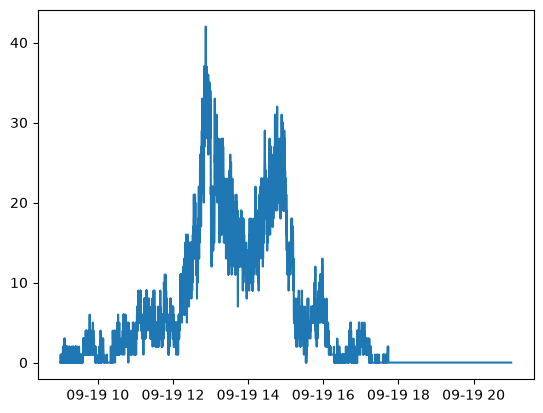

In [75]:
plt.plot(data['time'], data['people_amount'])
plt.show()

### Шаг 5. Проверка на стационарность
Тест Дики-Фуллера. Смотрим на «Вероятность» (p-value): грубо, если она меньше 0.05 - ряд можно считать стационарным.

In [76]:
result = adfuller(data['people_amount'])
print('Значение: %f' % result[0])
print('Вероятность: %f' % result[1])   # это и есть p-value
print('Пороговые значения:')
for key, value in result[4].items():
    print('\t%s: %.3f' % (key, value))

Значение: -1.861195
Вероятность: 0.350530
Пороговые значения:
	1%: -3.431
	5%: -2.862
	10%: -2.567


C:\Users\korko\AppData\Local\Temp\ipykernel_12864\470954570.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data['people_amount'])


### Шаг 6. Ресемплинг. Усреднение по 5 минут
Прореживаем частый ряд (шаг ~5 сек слишком мелкий).

In [77]:
# Группируем по 5-минутным интервалам и берём среднее внутри каждого
data = data.groupby(pd.Grouper(key='time', freq='5min')).mean().reset_index()
data
# Удалён устаревший параметр axis=0, не поддерживаемый в Pandas 3.x.

,time,people_amount
0,2025-09-19 09:00:00,0.438596
1,2025-09-19 09:05:00,0.929825
2,2025-09-19 09:10:00,0.500000
3,2025-09-19 09:15:00,0.620690
4,2025-09-19 09:20:00,0.741379
...,...,...
139,2025-09-19 20:35:00,0.000000
140,2025-09-19 20:40:00,0.000000
141,2025-09-19 20:45:00,0.000000
142,2025-09-19 20:50:00,0.000000


In [ ]:
data[['people_amount', 'without_trend', 'stat']].isna().sum() # .isna() - проверка отсутствующих значений, .sum() - количество таких значений в каждом столбце

people_amount    0
without_trend    5
stat             6
dtype: int64

### Шаг 7. Убираем тренд и берём разности
Получаем (стремимся получить) стационарный ряд.

In [78]:
# Вычитаем скользящее среднее по 6 точкам (6 × 5 мин = 30 минут) - убираем тренд
data['without_trend'] = data['people_amount'] - data['people_amount'].rolling(window=6).mean()
# Берём разности соседних значений - дифференцируем
data['stat'] = data['without_trend'].diff(periods=1).dropna()

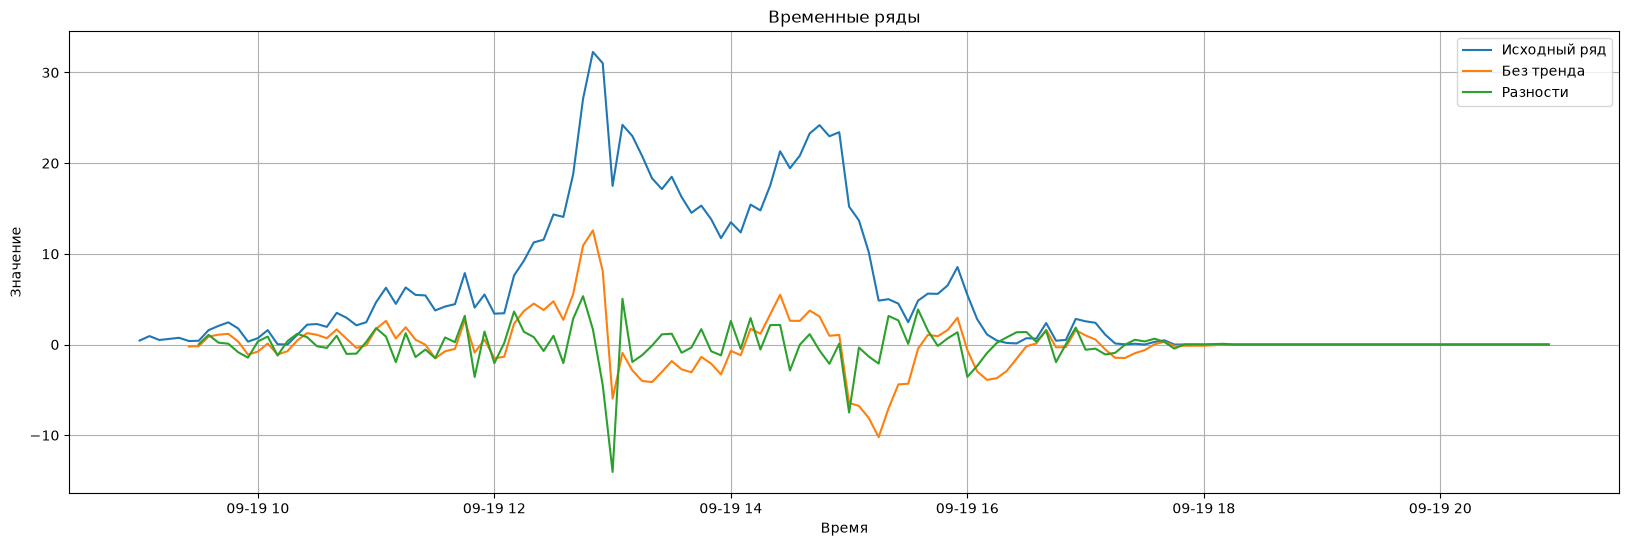

In [81]:
# plt.figure().set_figwidth(20)
# plt.plot(data['time'], data['people_amount'])
# plt.plot(data['time'], data['without_trend'])
# plt.plot(data['time'], data['stat'])
# plt.show()
plt.figure(figsize=(20, 6))

plt.plot(data['time'], data['people_amount'], label='Исходный ряд')
plt.plot(data['time'], data['without_trend'], label='Без тренда')
plt.plot(data['time'], data['stat'], label='Разности')

plt.title('Временные ряды')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.legend()
plt.grid(True)

plt.show()
#Синяя линия: people_amount.Это наши исходные данные после усреднения по 5 минутам. Мы видим, как менялось среднее количество людей.
#Оранжевая линия: without_trend Это данные, из которых вычли скользящее среднее за последние 30 минут. Мы убираем локальный уровень посещаемости и изучаем отклонения от него.
#Зелёная линия: stat Это разности соседних значений оранжевой линии. Мы смотрим, насколько изменилось отклонение от одного пятиминутного интервала к следующему.

### Шаг 8. Автокорреляция (ACF) и частичная автокорреляция (PACF)
Нужны для подбора параметров ARIMA. Пока достаточно уметь их строить и в общих чертах читать.

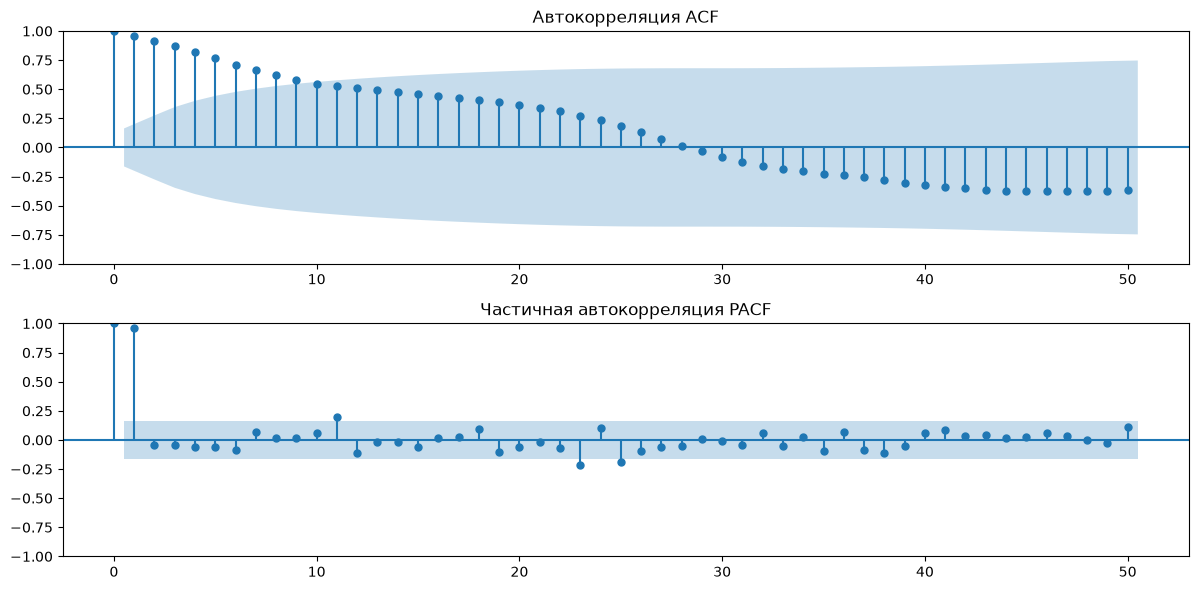

In [83]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.figure(figsize=(12, 6))
plt.subplot(211)
plot_acf(data['people_amount'], lags=50, ax=plt.gca())
plt.title('Автокорреляция ACF')

plt.subplot(212)
plot_pacf(data['people_amount'], lags=50, ax=plt.gca())
plt.title('Частичная автокорреляция PACF')

plt.tight_layout()
plt.show()

На графике ACF наблюдается высокая положительная автокорреляция на первых лагах, которая постепенно уменьшается. Это свидетельствует о выраженной зависимости между соседними значениями временного ряда.

На графике PACF наиболее заметен первый лаг, что позволяет рассмотреть параметр p=1 как один из начальных вариантов для модели ARIMA.

### Шаг 9. Обучение модели ARIMA
Параметры задаются как `order=(p, d, q)`.

In [85]:
from statsmodels.tsa.arima.model import ARIMA

# Обучение модели ARIMA
model = ARIMA(data['people_amount'], order=(1, 1, 1))   # (p, d, q)
model_fit = model.fit()

# Вывод статистики модели
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:          people_amount   No. Observations:                  144
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -315.007
Date:                Sat, 17 Oct 2026   AIC                            636.015
Time:                        13:18:29   BIC                            644.903
Sample:                             0   HQIC                           639.626
                                - 144                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5728      0.597      0.960      0.337      -0.597       1.742
ma.L1         -0.5403      0.606     -0.892      0.372      -1.727       0.647
sigma2         4.7961      0.272     17.648      0.0

c:\Users\korko\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\korko\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


На данном этапе была обучена модель ARIMA(1,1,1) на временном ряде после пятиминутного ресемплинга. 
Для обучения использовались 144 наблюдения. Значение AIC составило 636.015

### Шаг 10. Диагностика модели

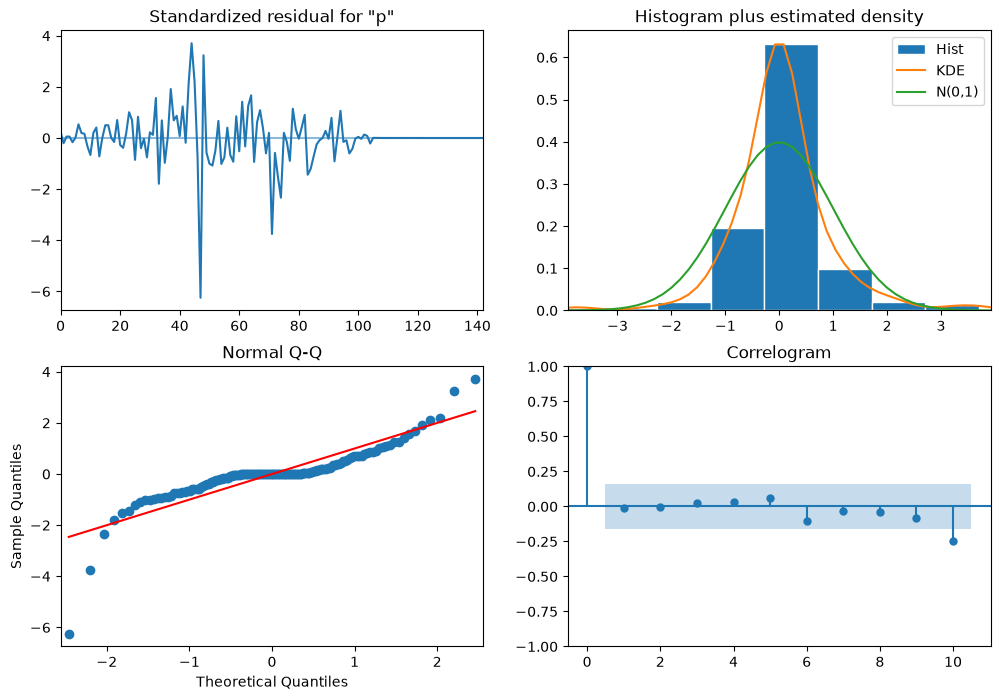

In [87]:
model_fit.plot_diagnostics(figsize=(12, 8))
plt.show()

### Шаг 11. Сравнение прогноза и реальных значений

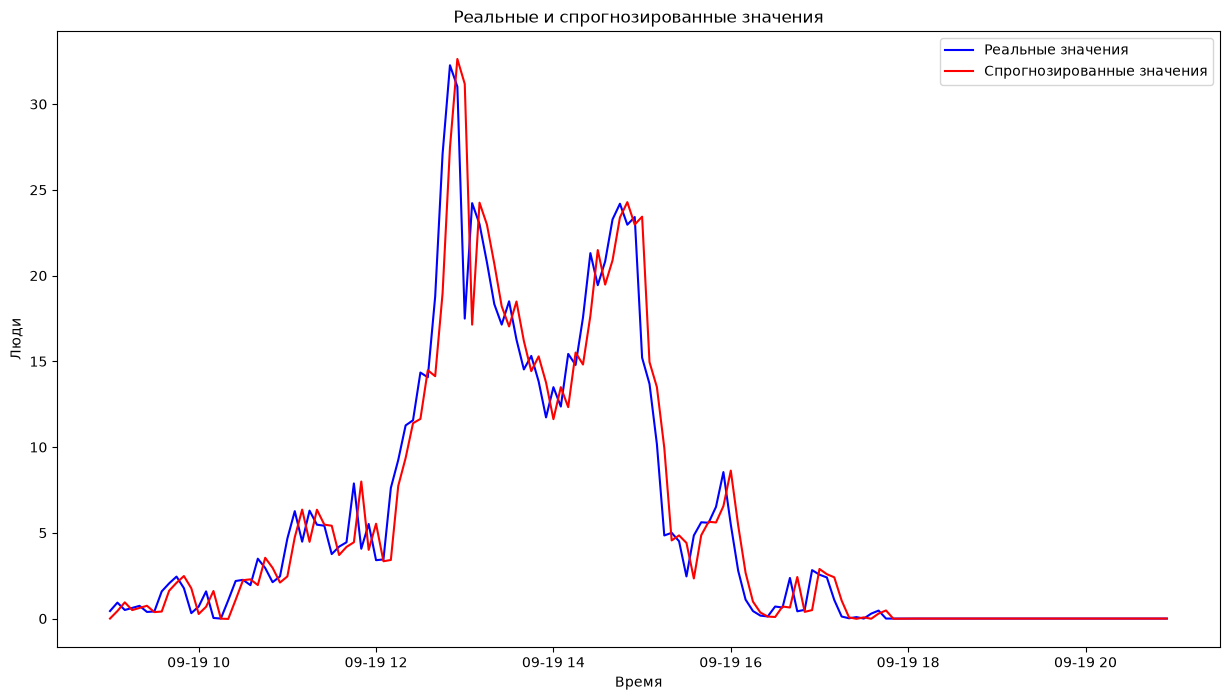

In [88]:
st_pred = model_fit.get_prediction()
forecast_values = st_pred.predicted_mean
plt.figure(figsize=(15, 8))
plt.plot(data['time'], data['people_amount'], label='Реальные значения', color='blue')
plt.plot(data['time'], forecast_values, label='Спрогнозированные значения', color='red')
plt.title('Реальные и спрогнозированные значения')
plt.xlabel('Время')
plt.ylabel('Люди')
plt.legend()
plt.show()